In [ ]:
# 1. Automatically install Ultralytics, gTTS, and PyYAML in the new session
!pip install -q ultralytics gtts pyyaml

# 2. Import libraries and initialize the system
import os
import zipfile
import yaml
from google.colab import drive
from ultralytics import YOLO

# 3. Mount Google Drive to save model weights and access the dataset
print("🔗 Mounting Google Drive...")
drive.mount('/content/drive')

# 4. [Automatic] Check for the dataset and extract it if needed
zip_path = '/content/drive/MyDrive/Offline Arabic ADAS.yolov11.zip'
dataset_dir = '/content/dataset'

if not os.path.exists(dataset_dir):
    print("📦 The 'dataset' directory is not available locally in Colab (due to a session restart).")
    if os.path.exists(zip_path):
        print("⚡ Extracting the dataset from Google Drive... This may take a minute...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(dataset_dir)
        print("✅ Dataset extracted successfully to the 'dataset' directory!")
    else:
        # Dynamically search Google Drive if the ZIP file was moved or renamed
        print("🔍 The default path was not found. Searching Google Drive for the dataset ZIP file...")
        found_zip = None
        for root, dirs, files in os.walk('/content/drive/MyDrive'):
            for file in files:
                if file.endswith('.zip') and ('ADAS' in file or 'YOLO' in file or 'yolov11' in file):
                    found_zip = os.path.join(root, file)
                    break
            if found_zip:
                break

        if found_zip:
            print(f"📦 Dataset ZIP file found at: {found_zip}")
            print("⚡ Extracting the dataset...")
            with zipfile.ZipFile(found_zip, 'r') as zip_ref:
                zip_ref.extractall(dataset_dir)
            print("✅ Dataset extracted successfully!")
        else:
            raise FileNotFoundError(f"❌ Dataset ZIP file (.zip) was not found in Google Drive!\nMake sure 'Offline Arabic ADAS.yolov11.zip' is uploaded to your Google Drive.")
else:
    print("✅ The 'dataset' directory is ready!")

# 5. Load the custom model weights for fine-tuning
SENDER_MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt"

if not os.path.exists(SENDER_MODEL_PATH):
    raise FileNotFoundError(f"❌ Model not found at: {SENDER_MODEL_PATH}\nCheck the weights path in Google Drive.")

print("🚀 Custom VISION model loaded successfully as the training base!")
model = YOLO(SENDER_MODEL_PATH)

# 6. Automatically locate data.yaml and correct dataset paths
yaml_path = None
for root, dirs, files_list in os.walk(dataset_dir):
    if 'data.yaml' in files_list:
        yaml_path = os.path.join(root, 'data.yaml')
        break

if yaml_path:
    print(f"🎯 Configuration file located successfully at: {yaml_path}")
    with open(yaml_path, 'r') as f:
        data_config = yaml.safe_load(f)

    # Correct the base path to match the internal Colab dataset structure
    data_config['path'] = os.path.dirname(yaml_path)

    with open(yaml_path, 'w') as f:
        yaml.dump(data_config, f)
    print("✅ Dataset paths corrected successfully!")
else:
    raise FileNotFoundError("❌ data.yaml was not found inside the dataset directory after extraction!")

# 7. Start the 100-epoch training with classification penalty and Drive checkpoint saving
print("🏋️ Starting final training for 100 Epochs...")
results = model.train(
    data=yaml_path,                    # Use the automatically detected configuration file
    epochs=100,                        # Number of training epochs
    imgsz=640,                         # Input image size
    batch=16,                          # Batch size for the T4 GPU

    # 🚨 Condition 1: Classification Loss Penalty to improve weaker classes
    cls=1.5,

    # 🚨 Condition 2: Save training results directly to Google Drive
    project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train",
    name="vision_heavy_penalty",
    exist_ok=True,

    # 🚨 Condition 3: Save checkpoints and the best model automatically
    save=True,
    save_period=1,

    patience=20,                       # Early stopping to reduce unnecessary GPU usage
    verbose=True
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 7.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.28.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. F

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving WhatsApp Image 2026-09-07 at 3.39.12 PM.jpeg to WhatsApp Image 2026-09-07 at 3.39.12 PM (2).jpeg

📦 تم رفع الملف: WhatsApp Image 2026-09-07 at 3.39.12 PM (2).jpeg
⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...

image 1/1 /content/WhatsApp Image 2026-09-07 at 3.39.12 PM (2).jpeg: 640x480 (no detections), 7.8ms
Speed: 1.7ms preprocess, 7.8ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/image_predictions

📊 --- الأجسام المكتشفة داخل الصورة ---
⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.


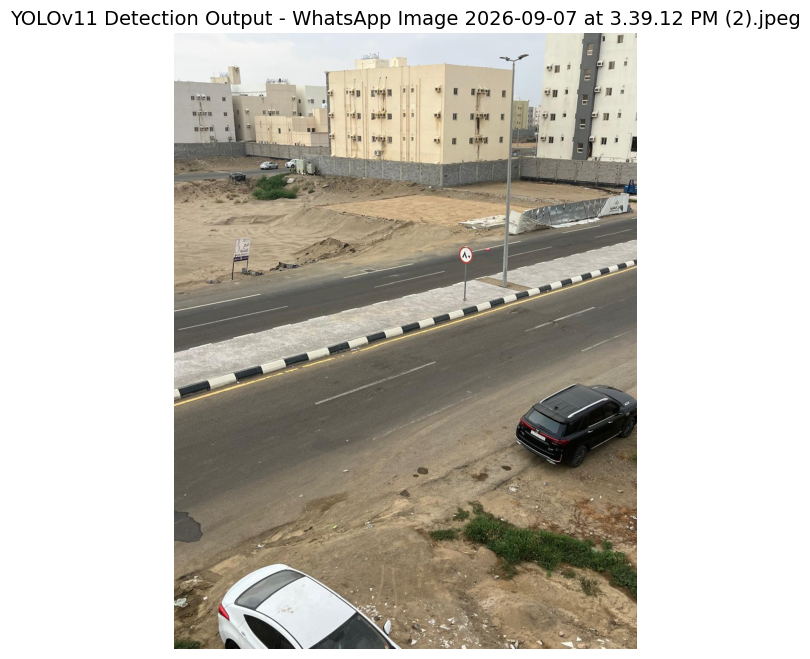


💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:
👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# 1. تحميل أفضل أوزان معتمدة من Google Drive
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان! تأكد من المسار التالي في الدرايف:")
    print(MODEL_PATH)
else:
    print("🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    # 2. طلب رفع الصورة من المستخدم
    uploaded = files.upload()

    if uploaded:
        image_filename = list(uploaded.keys())[0]
        print(f"\n📦 تم رفع الملف: {image_filename}")
        print("⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...")

        model = YOLO(MODEL_PATH)

        # 3. تشغيل التوقع مع حفظ النتيجة في الدرايف
        results = model.predict(
            source=image_filename,
            conf=0.25,  # عتبة الثقة 25%
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="image_predictions",
            exist_ok=True
        )

        # 4. طباعة التفاصيل النصية للأجسام المكتشفة (اسم الفئة ونسبة الثقة)
        print("\n📊 --- الأجسام المكتشفة داخل الصورة ---")
        boxes = results[0].boxes
        if len(boxes) == 0:
            print("⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.")
        else:
            for i, box in enumerate(boxes):
                cls_id = int(box.cls[0])
                class_name = model.names[cls_id]
                confidence = float(box.conf[0]) * 100
                print(f"  • الجسم [{i+1}]: {class_name} | نسبة الثقة: {confidence:.1f}%")

        # 5. عرض الصورة مع المربعات والأسماء ونسب الثقة
        annotated_frame = results[0].plot()  # يرسم المربعات، الاسم، ونسبة الثقة تلقائياً
        annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 8))
        plt.imshow(annotated_frame_rgb)
        plt.title(f"YOLOv11 Detection Output - {image_filename}", fontsize=14)
        plt.axis('off')
        plt.show()

        print("\n💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:")
        print("👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/")

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving سرعة80 صور (1).jpeg to سرعة80 صور (1).jpeg

📦 تم رفع الملف: سرعة80 صور (1).jpeg
⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...

image 1/1 /content/سرعة80 صور (1).jpeg: 640x384 (no detections), 12.5ms
Speed: 2.8ms preprocess, 12.5ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/image_predictions

📊 --- الأجسام المكتشفة داخل الصورة ---
⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.


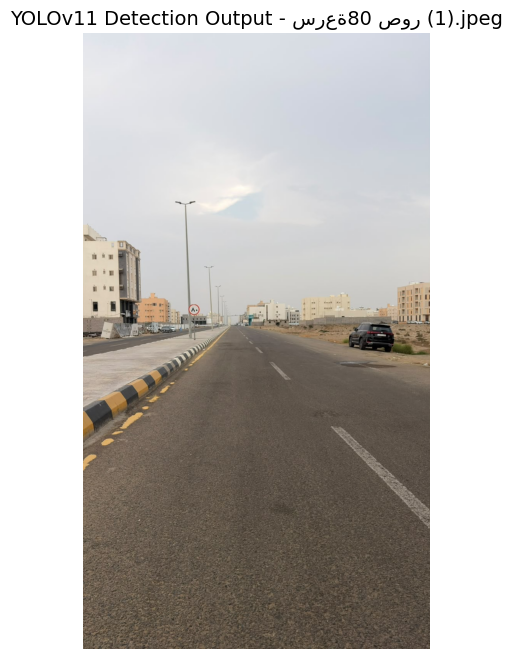


💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:
👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# 1. تحميل أفضل أوزان معتمدة من Google Drive
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان! تأكد من المسار التالي في الدرايف:")
    print(MODEL_PATH)
else:
    print("🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    # 2. طلب رفع الصورة من المستخدم
    uploaded = files.upload()

    if uploaded:
        image_filename = list(uploaded.keys())[0]
        print(f"\n📦 تم رفع الملف: {image_filename}")
        print("⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...")

        model = YOLO(MODEL_PATH)

        # 3. تشغيل التوقع مع حفظ النتيجة في الدرايف
        results = model.predict(
            source=image_filename,
            conf=0.25,  # عتبة الثقة 25%
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="image_predictions",
            exist_ok=True
        )

        # 4. طباعة التفاصيل النصية للأجسام المكتشفة (اسم الفئة ونسبة الثقة)
        print("\n📊 --- الأجسام المكتشفة داخل الصورة ---")
        boxes = results[0].boxes
        if len(boxes) == 0:
            print("⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.")
        else:
            for i, box in enumerate(boxes):
                cls_id = int(box.cls[0])
                class_name = model.names[cls_id]
                confidence = float(box.conf[0]) * 100
                print(f"  • الجسم [{i+1}]: {class_name} | نسبة الثقة: {confidence:.1f}%")

        # 5. عرض الصورة مع المربعات والأسماء ونسب الثقة
        annotated_frame = results[0].plot()  # يرسم المربعات، الاسم، ونسبة الثقة تلقائياً
        annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 8))
        plt.imshow(annotated_frame_rgb)
        plt.title(f"YOLOv11 Detection Output - {image_filename}", fontsize=14)
        plt.axis('off')
        plt.show()

        print("\n💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:")
        print("👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/")

🔗 جاري ربط Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ تم العثور على الأوزان بنجاح في المسار:
/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving لقطة شاشة 2026-09-07 160031.png to لقطة شاشة 2026-09-07 160031.png
🚀 جاري الاستدلال المطور بدقة عالية...

0: 544x1280 1 pedestrian, 1 pedestrian_crossing_sign, 374.0ms
Speed: 21.3ms preprocess, 374.0ms inference, 5.6ms postprocess per image at shape (1, 3, 544, 1280)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/high_res_predictions


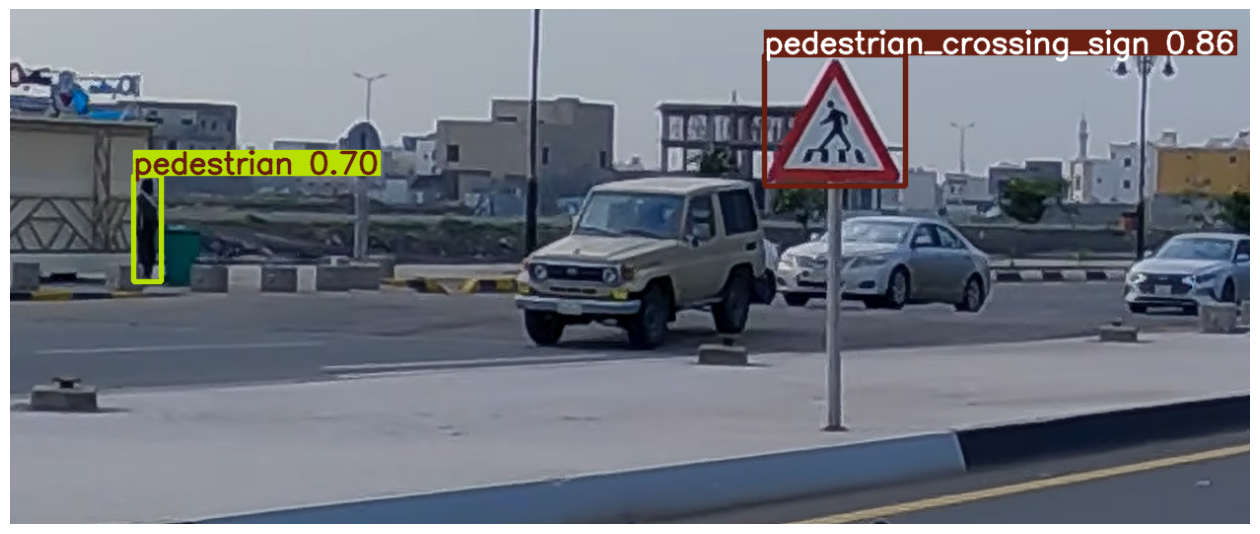

✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!


In [ ]:
# 1. تثبيت المكتبة
!pip install -q ultralytics

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import drive, files
from ultralytics import YOLO

# 2. ربط Google Drive بالجلسة لقراءة الأوزان
print("🔗 جاري ربط Google Drive...")
drive.mount("/content/drive", force_remount=False)

# 3. تحديد مسار الأوزان (تأكد من وجود الملف في هذا المسار)
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt"

# إذا لم يجد الأوزان في المسار القديم، سيفحص المسار النهائي المطور تلقائياً
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان!")
    print("تأكد من وجود ملف best.pt داخل مجلد ADAS_YOLOv11_Model في قوقل درايف.")
else:
    print(f"✅ تم العثور على الأوزان بنجاح في المسار:\n{MODEL_PATH}")
    print("\n🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    uploaded = files.upload()

    if uploaded:
        IMAGE_PATH = list(uploaded.keys())[0]

        # 4. قراءة الصورة وتحويل الألوان إلى RGB
        img_bgr = cv2.imread(IMAGE_PATH)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 5. تحميل النموذج وتشغيل التوقع بدقة 1280
        model = YOLO(MODEL_PATH)
        print("🚀 جاري الاستدلال المطور بدقة عالية...")

        results = model.predict(
            source=img_rgb,
            imgsz=1280,
            conf=0.20,
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="high_res_predictions",
            exist_ok=True,
        )

        # 6. عرض الصورة الناتجة
        annotated_frame = results[0].plot()
        plt.figure(figsize=(16, 10))
        plt.imshow(annotated_frame)
        plt.axis("off")
        plt.show()
        print("✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!")

🔗 جاري ربط Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ تم العثور على الأوزان بنجاح في المسار:
/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving سرعة80 صور (1).jpeg to سرعة80 صور (1).jpeg
🚀 جاري الاستدلال المطور بدقة عالية...

0: 1280x736 1 speed_80, 650.3ms
Speed: 28.0ms preprocess, 650.3ms inference, 1.8ms postprocess per image at shape (1, 3, 1280, 736)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/high_res_predictions


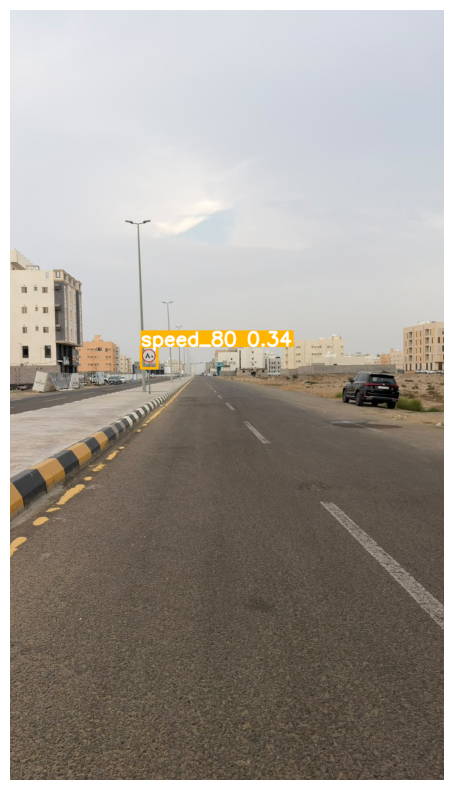

✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!


In [ ]:
# 1. تثبيت المكتبة
!pip install -q ultralytics

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import drive, files
from ultralytics import YOLO

# 2. ربط Google Drive بالجلسة لقراءة الأوزان
print("🔗 جاري ربط Google Drive...")
drive.mount("/content/drive", force_remount=False)

# 3. تحديد مسار الأوزان (تأكد من وجود الملف في هذا المسار)
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt"

# إذا لم يجد الأوزان في المسار القديم، سيفحص المسار النهائي المطور تلقائياً
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان!")
    print("تأكد من وجود ملف best.pt داخل مجلد ADAS_YOLOv11_Model في قوقل درايف.")
else:
    print(f"✅ تم العثور على الأوزان بنجاح في المسار:\n{MODEL_PATH}")
    print("\n🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    uploaded = files.upload()

    if uploaded:
        IMAGE_PATH = list(uploaded.keys())[0]

        # 4. قراءة الصورة وتحويل الألوان إلى RGB
        img_bgr = cv2.imread(IMAGE_PATH)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 5. تحميل النموذج وتشغيل التوقع بدقة 1280
        model = YOLO(MODEL_PATH)
        print("🚀 جاري الاستدلال المطور بدقة عالية...")

        results = model.predict(
            source=img_rgb,
            imgsz=1280,
            conf=0.20,
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="high_res_predictions",
            exist_ok=True,
        )

        # 6. عرض الصورة الناتجة
        annotated_frame = results[0].plot()
        plt.figure(figsize=(16, 10))
        plt.imshow(annotated_frame)
        plt.axis("off")
        plt.show()
        print("✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!")

🔗 جاري ربط Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ تم العثور على الأوزان بنجاح في المسار:
/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving لقطة شاشة 2026-09-07 155845.png to لقطة شاشة 2026-09-07 155845.png
🚀 جاري الاستدلال المطور بدقة عالية...

0: 384x1280 1 speed_bump, 256.3ms
Speed: 8.1ms preprocess, 256.3ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 1280)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/high_res_predictions


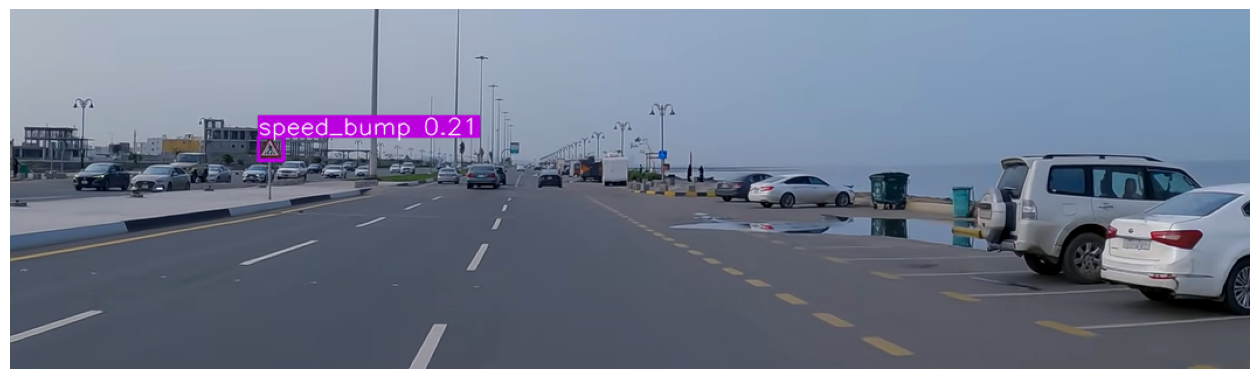

✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!


In [ ]:
# 1. تثبيت المكتبة
!pip install -q ultralytics

import os
import cv2
import matplotlib.pyplot as plt
from google.colab import drive, files
from ultralytics import YOLO

# 2. ربط Google Drive بالجلسة لقراءة الأوزان
print("🔗 جاري ربط Google Drive...")
drive.mount("/content/drive", force_remount=False)

# 3. تحديد مسار الأوزان (تأكد من وجود الملف في هذا المسار)
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/weights/best.pt"

# إذا لم يجد الأوزان في المسار القديم، سيفحص المسار النهائي المطور تلقائياً
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان!")
    print("تأكد من وجود ملف best.pt داخل مجلد ADAS_YOLOv11_Model في قوقل درايف.")
else:
    print(f"✅ تم العثور على الأوزان بنجاح في المسار:\n{MODEL_PATH}")
    print("\n🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    uploaded = files.upload()

    if uploaded:
        IMAGE_PATH = list(uploaded.keys())[0]

        # 4. قراءة الصورة وتحويل الألوان إلى RGB
        img_bgr = cv2.imread(IMAGE_PATH)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 5. تحميل النموذج وتشغيل التوقع بدقة 1280
        model = YOLO(MODEL_PATH)
        print("🚀 جاري الاستدلال المطور بدقة عالية...")

        results = model.predict(
            source=img_rgb,
            imgsz=1280,
            conf=0.20,
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="high_res_predictions",
            exist_ok=True,
        )

        # 6. عرض الصورة الناتجة
        annotated_frame = results[0].plot()
        plt.figure(figsize=(16, 10))
        plt.imshow(annotated_frame)
        plt.axis("off")
        plt.show()
        print("✅ تم الاستدلال بنجاح وحفظ الصورة في Google Drive!")

🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...


Saving لقطة شاشة 2026-09-07 162802.png to لقطة شاشة 2026-09-07 162802.png

📦 تم رفع الملف: لقطة شاشة 2026-09-07 162802.png
⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...

image 1/1 /content/لقطة شاشة 2026-09-07 162802.png: 288x640 (no detections), 7.6ms
Speed: 1.7ms preprocess, 7.6ms inference, 0.7ms postprocess per image at shape (1, 3, 288, 640)
Results saved to /content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests/image_predictions

📊 --- الأجسام المكتشفة داخل الصورة ---
⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.


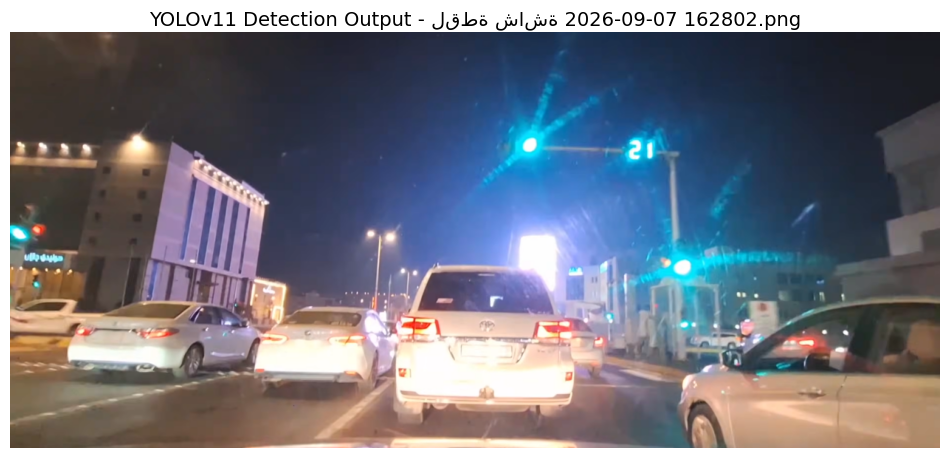


💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:
👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/


In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# 1. تحميل أفضل أوزان معتمدة من Google Drive
MODEL_PATH = "/content/drive/MyDrive/ADAS_YOLOv11_Model/Final_Train/vision_heavy_penalty/weights/best.pt"

if not os.path.exists(MODEL_PATH):
    print("❌ لم يتم العثور على ملف الأوزان! تأكد من المسار التالي في الدرايف:")
    print(MODEL_PATH)
else:
    print("🚀 الموديل جاهز! يرجى اختيار الصورة لرفعها من جهازك...")

    # 2. طلب رفع الصورة من المستخدم
    uploaded = files.upload()

    if uploaded:
        image_filename = list(uploaded.keys())[0]
        print(f"\n📦 تم رفع الملف: {image_filename}")
        print("⚡ جاري تشغيل الاستدلال وتحديد اللوحات والمشاة...")

        model = YOLO(MODEL_PATH)

        # 3. تشغيل التوقع مع حفظ النتيجة في الدرايف
        results = model.predict(
            source=image_filename,
            conf=0.25,  # عتبة الثقة 25%
            save=True,
            project="/content/drive/MyDrive/ADAS_YOLOv11_Model/Inference_Tests",
            name="image_predictions",
            exist_ok=True
        )

        # 4. طباعة التفاصيل النصية للأجسام المكتشفة (اسم الفئة ونسبة الثقة)
        print("\n📊 --- الأجسام المكتشفة داخل الصورة ---")
        boxes = results[0].boxes
        if len(boxes) == 0:
            print("⚠️ لم يتم العثور على أي أجسام بعتبة ثقة أعلى من 25%.")
        else:
            for i, box in enumerate(boxes):
                cls_id = int(box.cls[0])
                class_name = model.names[cls_id]
                confidence = float(box.conf[0]) * 100
                print(f"  • الجسم [{i+1}]: {class_name} | نسبة الثقة: {confidence:.1f}%")

        # 5. عرض الصورة مع المربعات والأسماء ونسب الثقة
        annotated_frame = results[0].plot()  # يرسم المربعات، الاسم، ونسبة الثقة تلقائياً
        annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 8))
        plt.imshow(annotated_frame_rgb)
        plt.title(f"YOLOv11 Detection Output - {image_filename}", fontsize=14)
        plt.axis('off')
        plt.show()

        print("\n💾 تم حفظ النسخة المكتشفة بنجاح في Google Drive تحت المجلد:")
        print("👉 ADAS_YOLOv11_Model/Inference_Tests/image_predictions/")